1. Khám phá và phân tích dữ liệu

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [2]:
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "official").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_FILE = PROJECT_ROOT / "experiments" / "datasets" / "exchange_rate.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset file:", DATASET_FILE)
print("File exists:", DATASET_FILE.exists())

Project root: d:\TVCFORMER
Dataset file: d:\TVCFORMER\experiments\datasets\exchange_rate.csv
File exists: True


In [3]:
df = pd.read_csv(DATASET_FILE)

print("Dataset: Exchange Rate")
print("Shape:", df.shape)
print("Column names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
display(df.head())

Dataset: Exchange Rate
Shape: (7588, 9)
Column names: ['date', '0', '1', '2', '3', '4', '5', '6', 'OT']

Data types:
date     object
0       float64
1       float64
2       float64
3       float64
4       float64
5       float64
6       float64
OT      float64
dtype: object

First 5 rows:


,date,0,1,2,3,4,5,6,OT
0,1990/1/1 0:00,0.7855,1.6110,0.861698,0.634196,0.211242,0.006838,0.525486,0.5930
1,1990/1/2 0:00,0.7818,1.6100,0.861104,0.633513,0.211242,0.006863,0.523972,0.5940
2,1990/1/3 0:00,0.7867,1.6293,0.861030,0.648508,0.211242,0.006975,0.526316,0.5973
3,1990/1/4 0:00,0.7860,1.6370,0.862069,0.650618,0.211242,0.006953,0.523834,0.5970
4,1990/1/5 0:00,0.7849,1.6530,0.861995,0.656254,0.211242,0.006940,0.527426,0.5985


2. Missing values

In [4]:
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))

print("\nMissing percentage (%):")
display((df.isna().mean() * 100).to_frame("missing_percent"))

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Missing values:


,missing_count
date,0
0,0
1,0
2,0
3,0
4,0
5,0
6,0
OT,0



Missing percentage (%):


,missing_percent
date,0.0
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
5,0.0
6,0.0
OT,0.0



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,7588,7588,1990/1/1 0:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,7588.0,NaN,NaN,NaN,0.776974,0.13662,0.483297,0.701422,0.761377,0.873477,1.102536
1,7588.0,NaN,NaN,NaN,1.634105,0.161544,1.211534,1.532887,1.606574,1.707646,2.109
2,7588.0,NaN,NaN,NaN,0.821811,0.117123,0.618582,0.727901,0.811582,0.920394,1.091524
3,7588.0,NaN,NaN,NaN,0.848146,0.168874,0.548617,0.696864,0.813959,1.014018,1.374079
4,7588.0,NaN,NaN,NaN,0.142833,0.023996,0.109292,0.120814,0.145212,0.159948,0.237954
5,7588.0,NaN,NaN,NaN,0.009343,0.001458,0.006254,0.008331,0.009151,0.009995,0.013202
6,7588.0,NaN,NaN,NaN,0.669673,0.082836,0.523834,0.593287,0.662767,0.731835,0.832556
OT,7588.0,NaN,NaN,NaN,0.654418,0.115292,0.393153,0.566,0.669187,0.734901,0.882379


3. Kiểm tra trùng lặp

In [5]:
duplicate_rows = df.duplicated().sum()

print("Số dòng trùng lặp hoàn toàn:", duplicate_rows)

if duplicate_rows > 0:
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("Không có dòng trùng lặp hoàn toàn.")

Số dòng trùng lặp hoàn toàn: 0
Không có dòng trùng lặp hoàn toàn.


4. Kiểm tra mốc thời gian

In [6]:
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    dates = df["date"]
    duplicated_dates = dates.duplicated(keep=False)

    print("Số ngày không hợp lệ:", dates.isna().sum())
    print("Số dòng có timestamp trùng:", duplicated_dates.sum())
    print("Số timestamp trùng khác nhau:", dates[duplicated_dates].nunique())
    print("Thời điểm bắt đầu:", dates.min())
    print("Thời điểm kết thúc:", dates.max())

    if duplicated_dates.any():
        print("\nCác dòng có timestamp trùng:")
        display(
            df.loc[duplicated_dates]
            .sort_values("date")
            .head(10)
        )
else:
    print("Không tìm thấy cột date trong bộ dữ liệu.")


Số ngày không hợp lệ: 0
Số dòng có timestamp trùng: 0
Số timestamp trùng khác nhau: 0
Thời điểm bắt đầu: 1990-01-01 00:00:00
Thời điểm kết thúc: 2010-10-10 00:00:00


5. Phân tích chuỗi thời gian

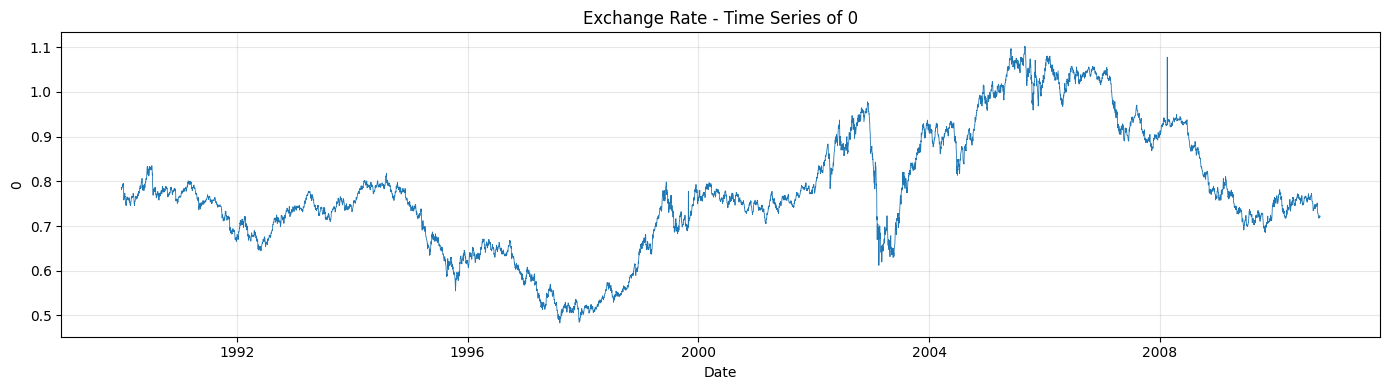

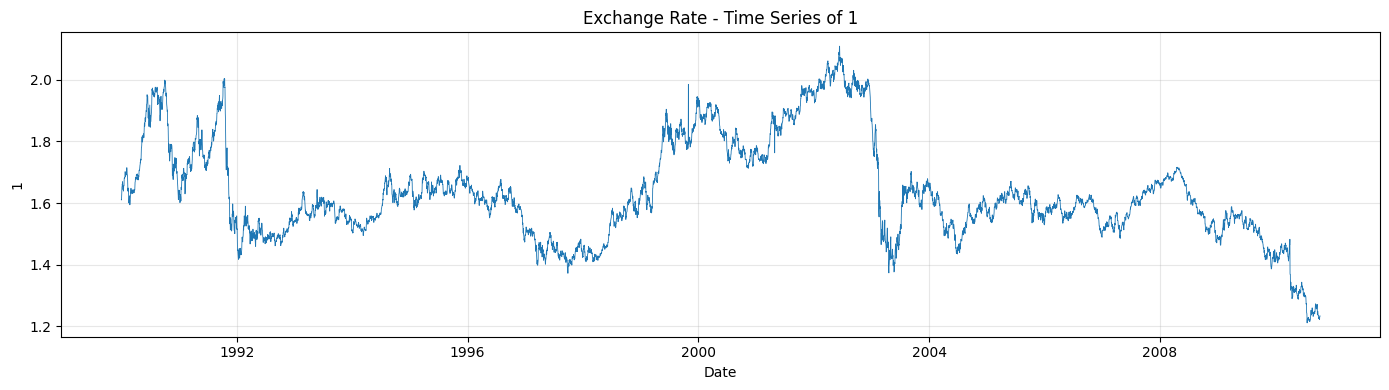

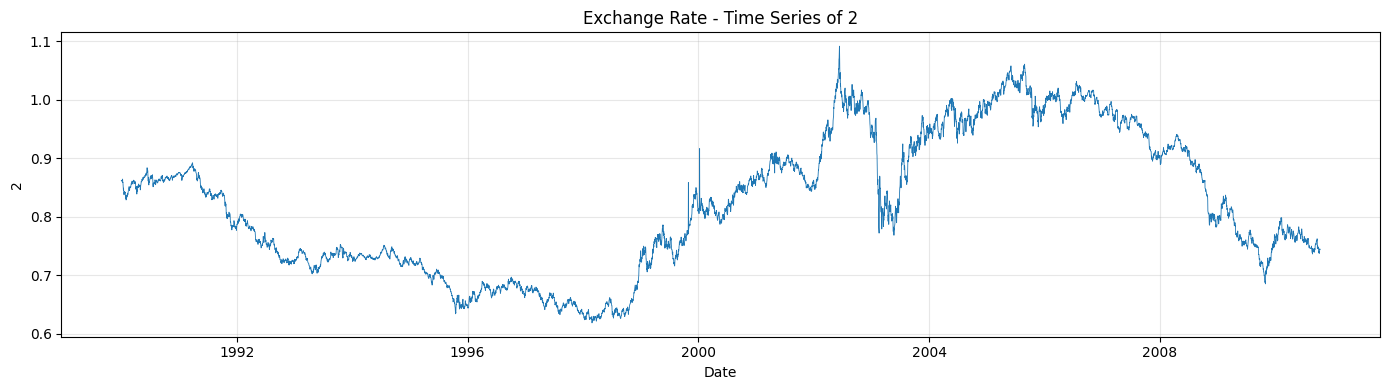

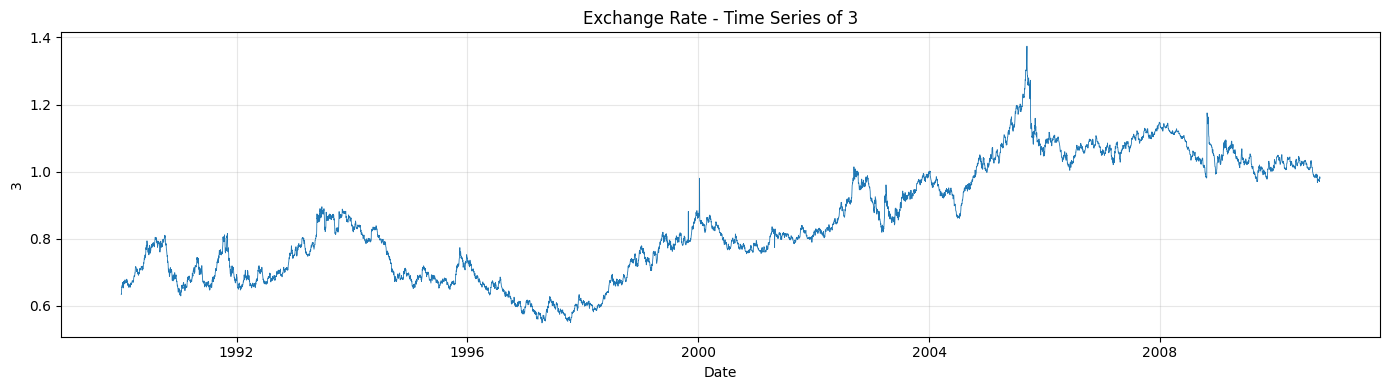

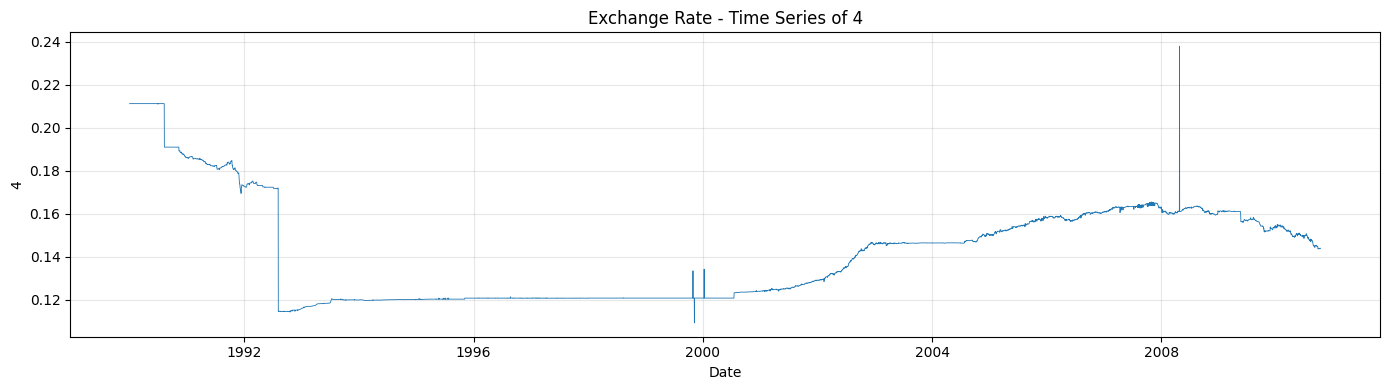

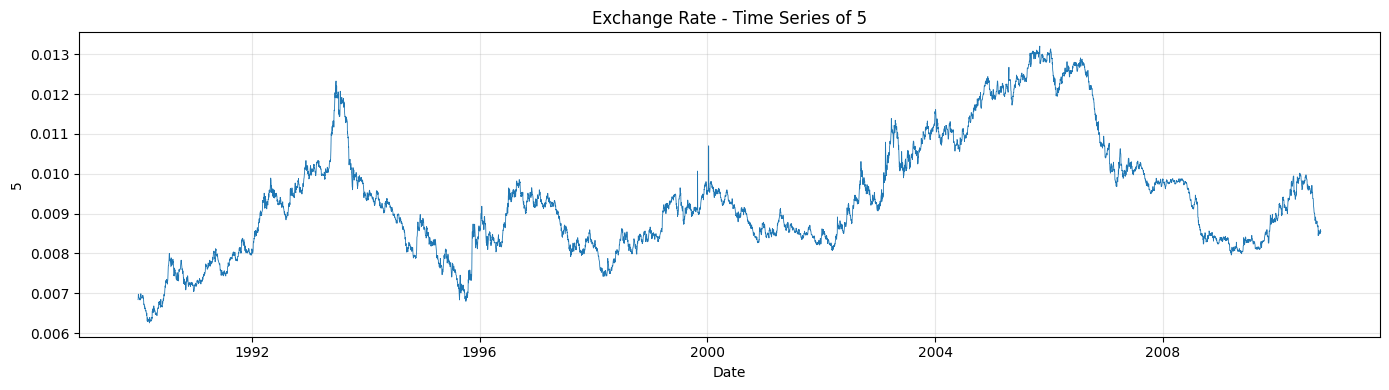

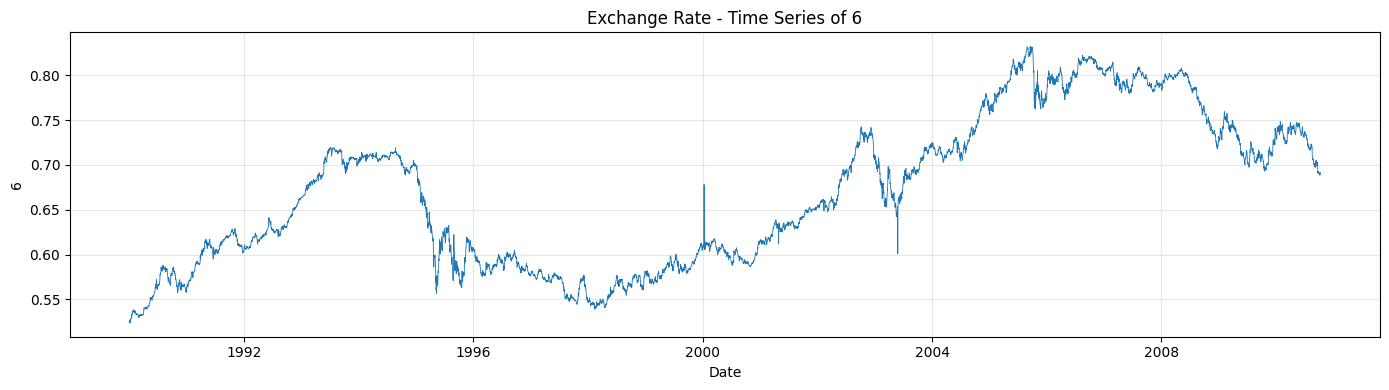

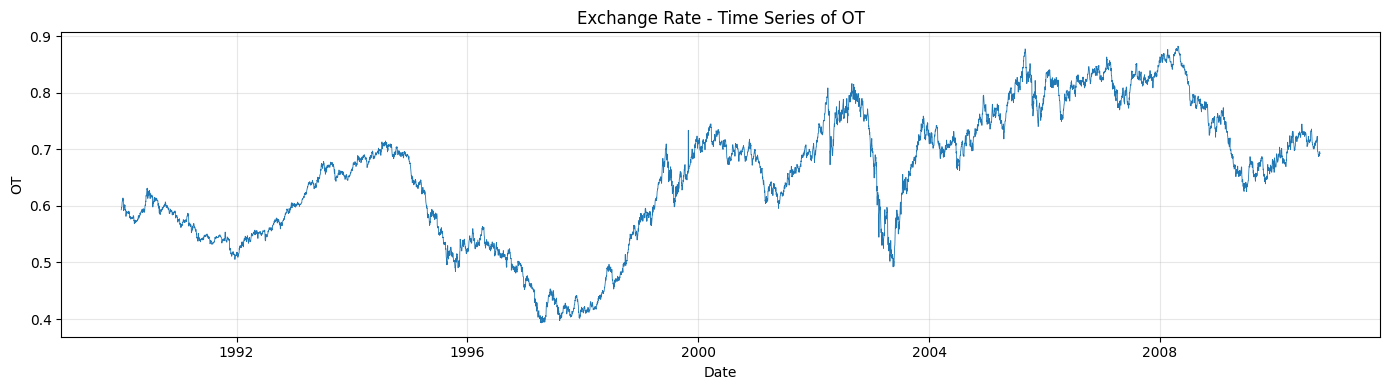

In [7]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

if "date" in df.columns:
    for col in numeric_cols:
        data = df.dropna(subset=["date", col]).sort_values("date")

        plt.figure(figsize=(14, 4))
        plt.plot(data["date"], data[col], linewidth=0.6)
        plt.title(f"Exchange Rate - Time Series of {col}")
        plt.xlabel("Date")
        plt.ylabel(col)
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
else:
    print("Bỏ qua biểu đồ chuỗi thời gian vì thiếu cột date.")

6. Phân tích phân phối các biến

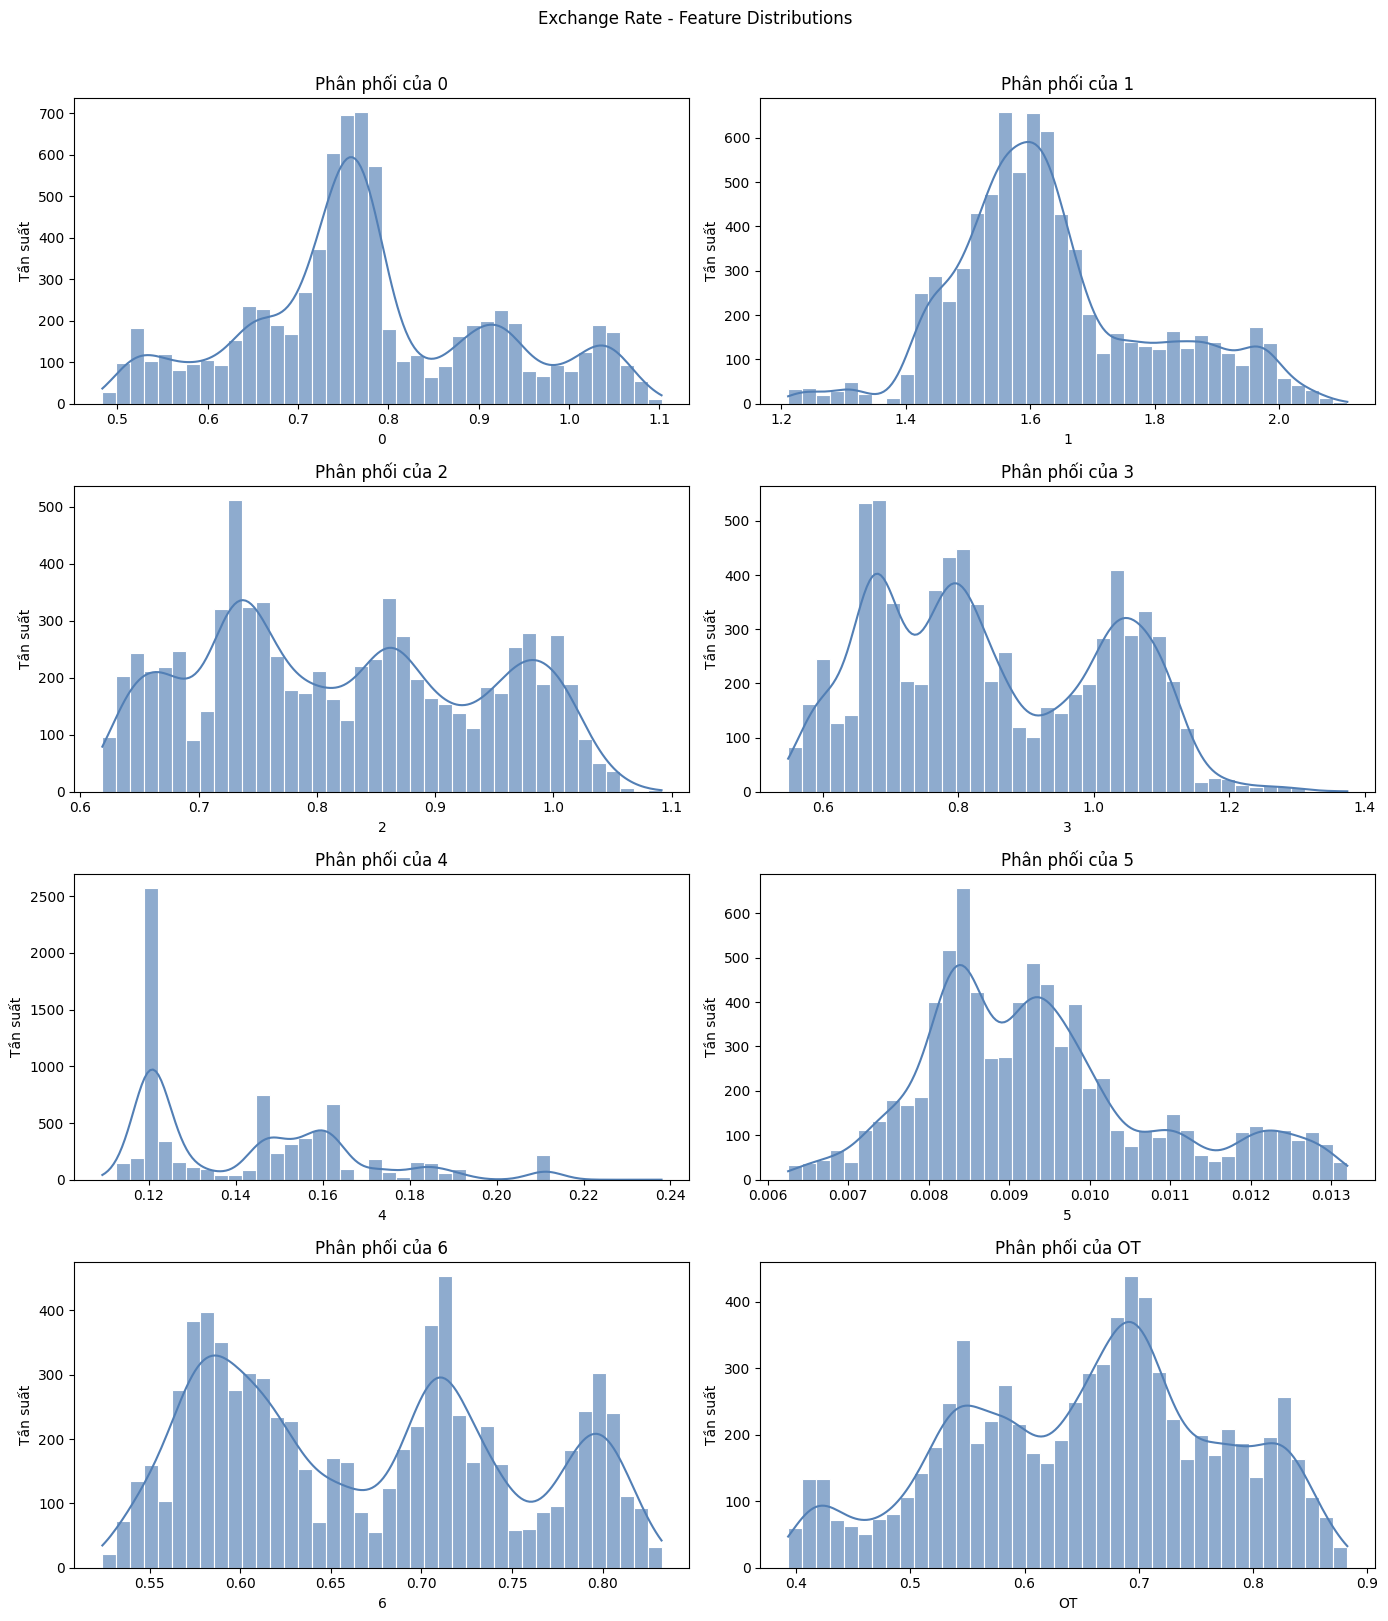

In [8]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

n_cols = 2
n_rows = math.ceil(len(numeric_cols) / n_cols)

if numeric_cols:
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(14, 4 * n_rows)
    )

    axes = np.asarray(axes).flatten()

    for i, col in enumerate(numeric_cols):
        sns.histplot(
            data=df,
            x=col,
            bins=40,
            kde=True,
            color="#527FB5",
            edgecolor="white",
            alpha=0.65,
            ax=axes[i]
        )
        axes[i].set_title(f"Phân phối của {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Tần suất")

    for i in range(len(numeric_cols), len(axes)):
        axes[i].set_visible(False)

    fig.suptitle("Exchange Rate - Feature Distributions", y=1.01)
    plt.tight_layout()
    plt.show()

7. Phân tích tương quan giữa các biến

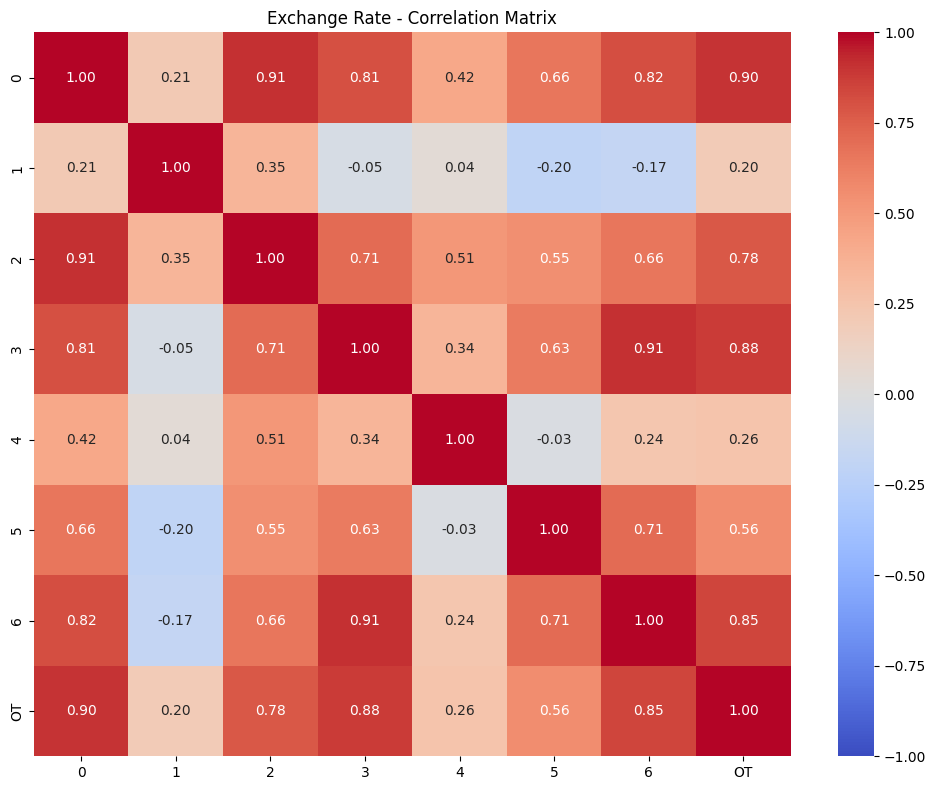

In [9]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Exchange Rate - Correlation Matrix")
plt.tight_layout()
plt.show()


8. Phân tích ngoại lệ bằng BoxPlot

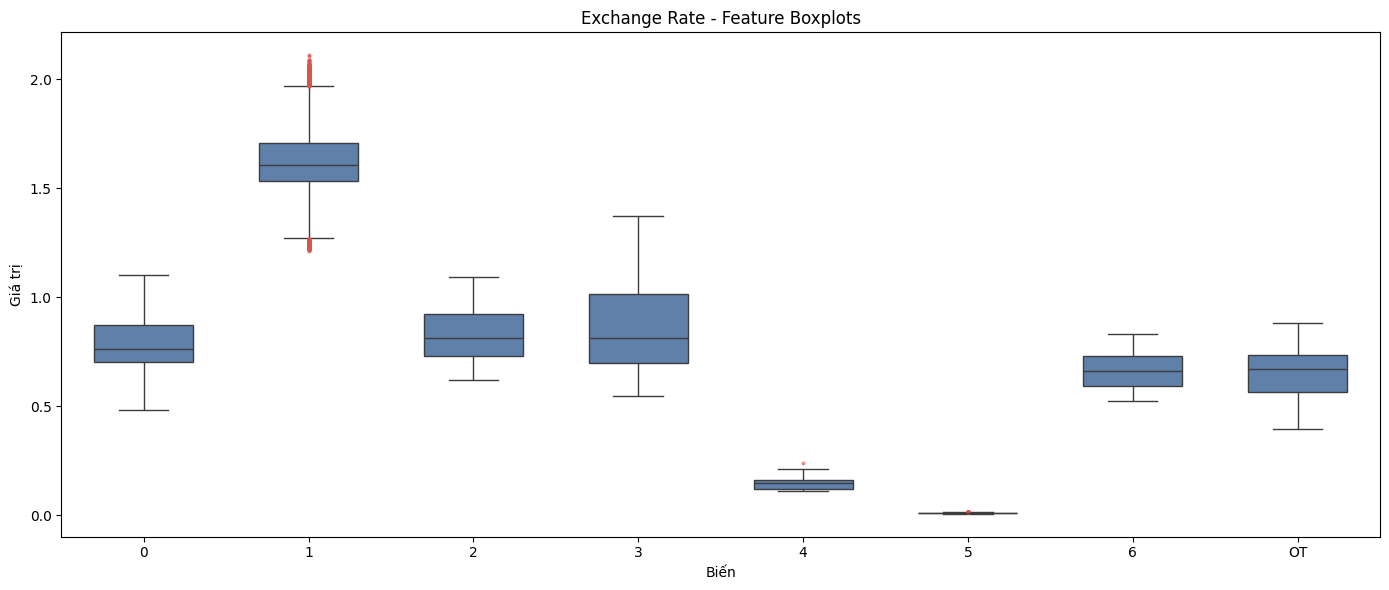

In [10]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

if numeric_cols:
    plt.figure(figsize=(14, 6))

    sns.boxplot(
        data=df[numeric_cols],
        color="#527FB5",
        width=0.6,
        flierprops={
            "marker": "o",
            "markersize": 2,
            "markerfacecolor": "#D9534F",
            "markeredgecolor": "#D9534F",
            "alpha": 0.5
        }
    )

    plt.title("Exchange Rate - Feature Boxplots")
    plt.xlabel("Biến")
    plt.ylabel("Giá trị")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [11]:
print("=" * 60)
print("EXCHANGE RATE DATASET OVERVIEW")
print("=" * 60)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

if "date" in df.columns:
    dates = pd.to_datetime(df["date"], errors="coerce")
    print("Start date:", dates.min())
    print("End date:", dates.max())

print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget configuration:")
if "OT" in df.columns:
    print("Bộ dữ liệu có cột OT.")
else:
    print("Không tìm thấy cột OT trong dữ liệu Exchange Rate.")
    print("Cần kiểm tra data loader và cấu hình của từng mô hình")
    print("để xác định cách chọn biến mục tiêu khi thực nghiệm.")

EXCHANGE RATE DATASET OVERVIEW
Shape: (7588, 9)
Columns: ['date', '0', '1', '2', '3', '4', '5', '6', 'OT']
Start date: 1990-01-01 00:00:00
End date: 2010-10-10 00:00:00
Missing values: 0
Duplicate rows: 0

Target configuration:
Bộ dữ liệu có cột OT.


9. P-value

In [16]:
import pandas as pd
from statsmodels.tsa.stattools import adfuller
df = df.drop(columns=["date"], errors="ignore")

for col in df.columns:
    series = pd.to_numeric(df[col], errors="coerce").dropna()
    adf_stat, p_value, *_ = adfuller(series)

    if p_value < 0.05:
        result = "Bac bo H0 - Co bang chung chuoi dung"
    else:
        result = "Chua du bang chung bac bo H0"

    print(
        f"{col}: ADF = {adf_stat:.4f} | "
        f"p-value = {p_value:.6f} | {result}"
    )

0: ADF = -1.6650 | p-value = 0.449233 | Chua du bang chung bac bo H0
1: ADF = -2.1497 | p-value = 0.224998 | Chua du bang chung bac bo H0
2: ADF = -1.3526 | p-value = 0.604791 | Chua du bang chung bac bo H0
3: ADF = -1.5867 | p-value = 0.490267 | Chua du bang chung bac bo H0
4: ADF = -2.8692 | p-value = 0.049052 | Bac bo H0 - Co bang chung chuoi dung
5: ADF = -2.1201 | p-value = 0.236501 | Chua du bang chung bac bo H0
6: ADF = -1.7477 | p-value = 0.406701 | Chua du bang chung bac bo H0
OT: ADF = -1.7282 | p-value = 0.416646 | Chua du bang chung bac bo H0


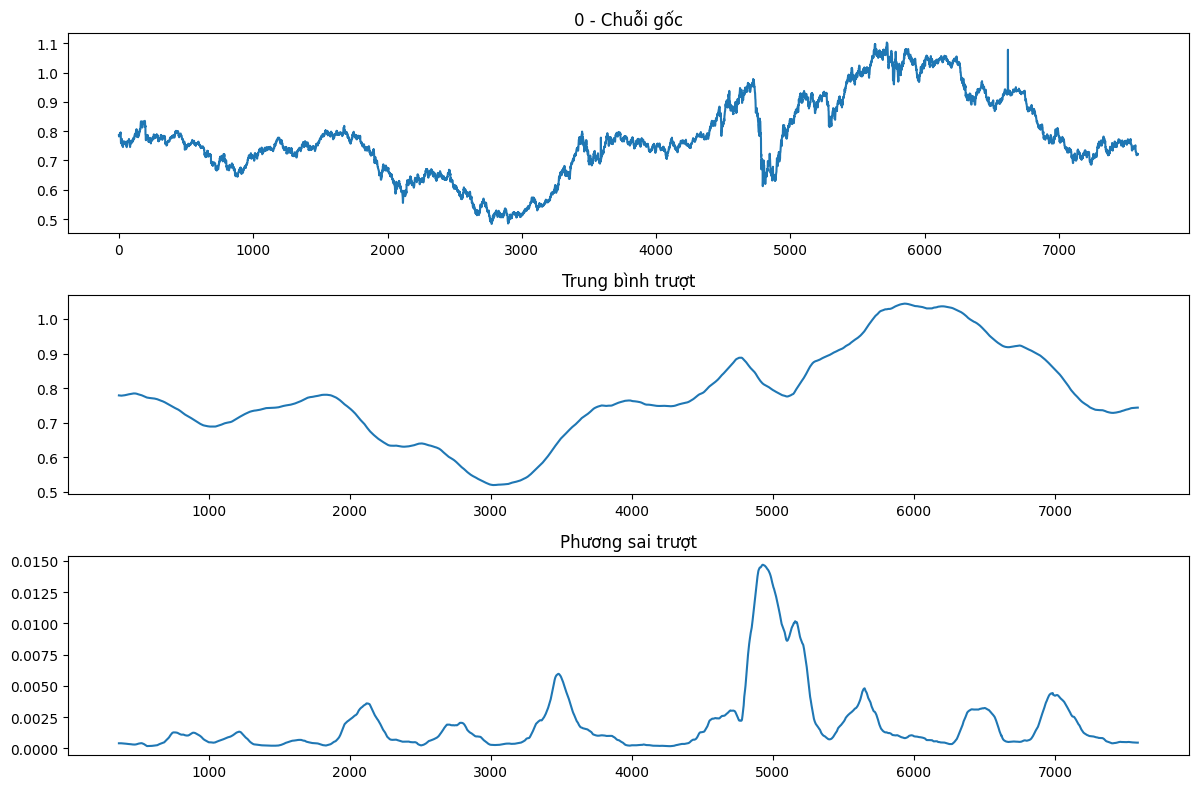

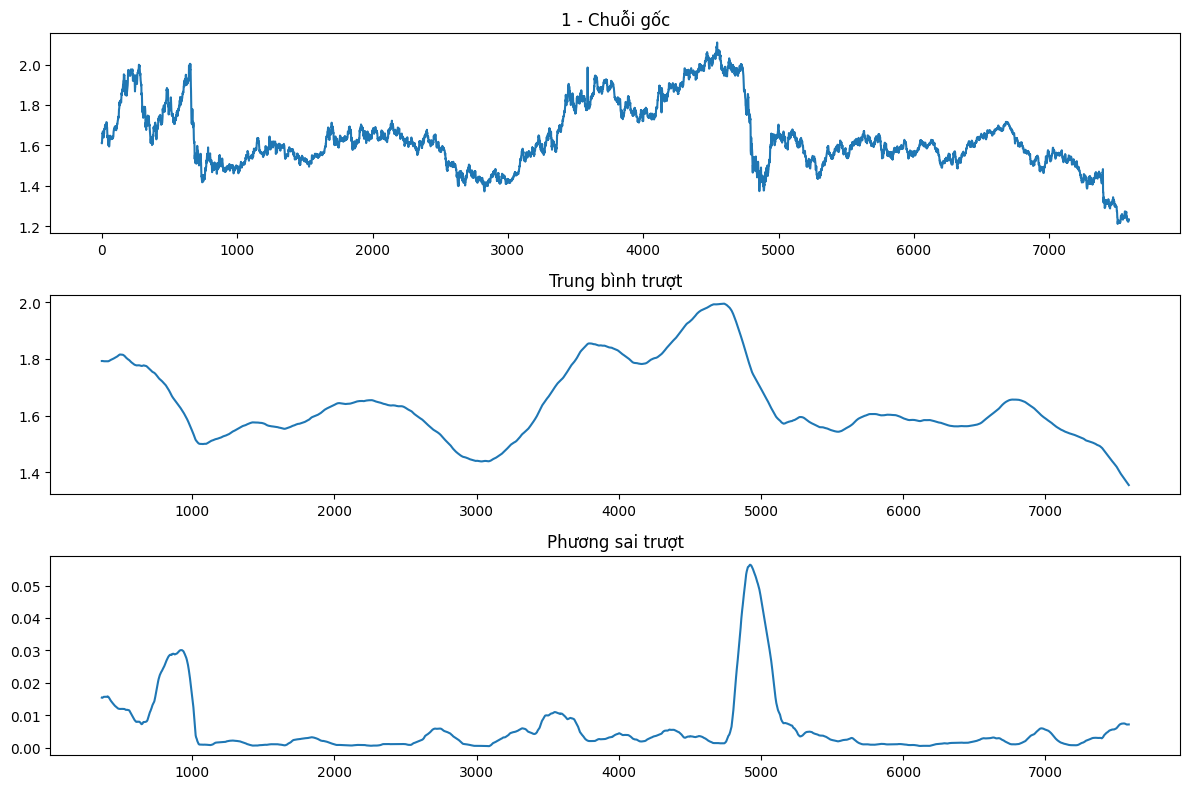

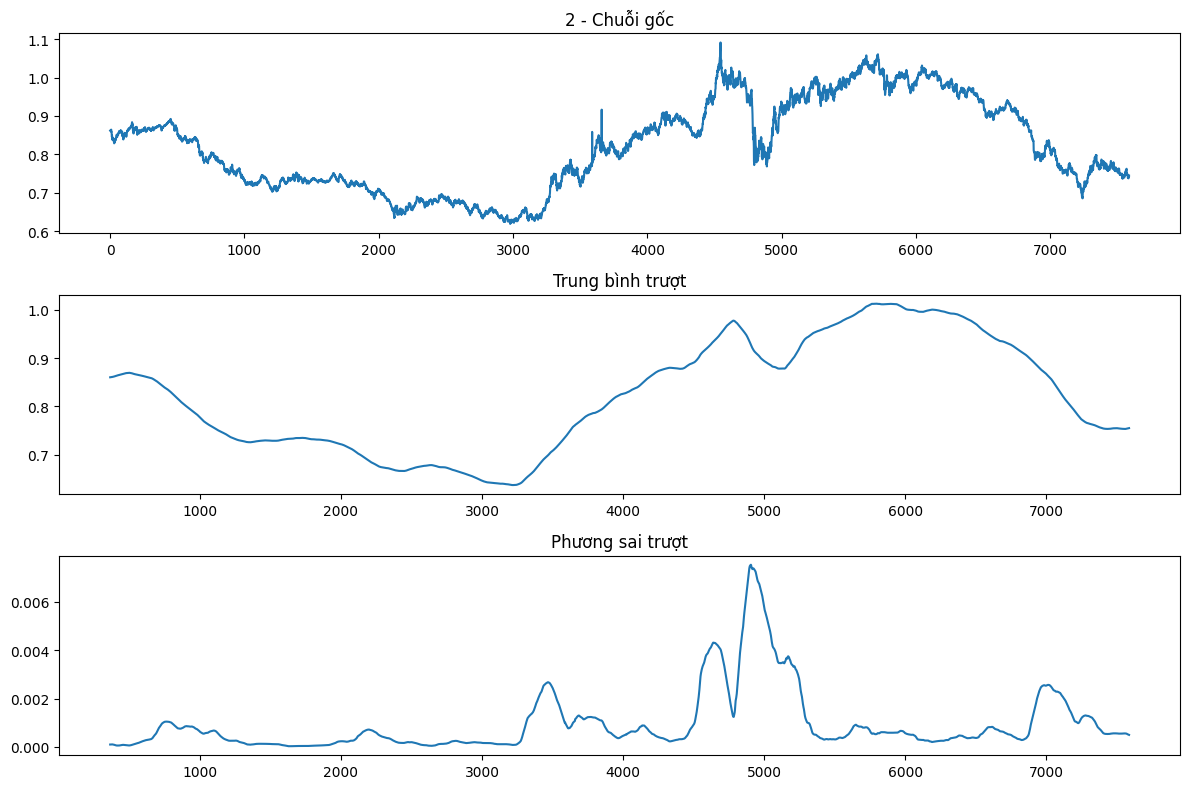

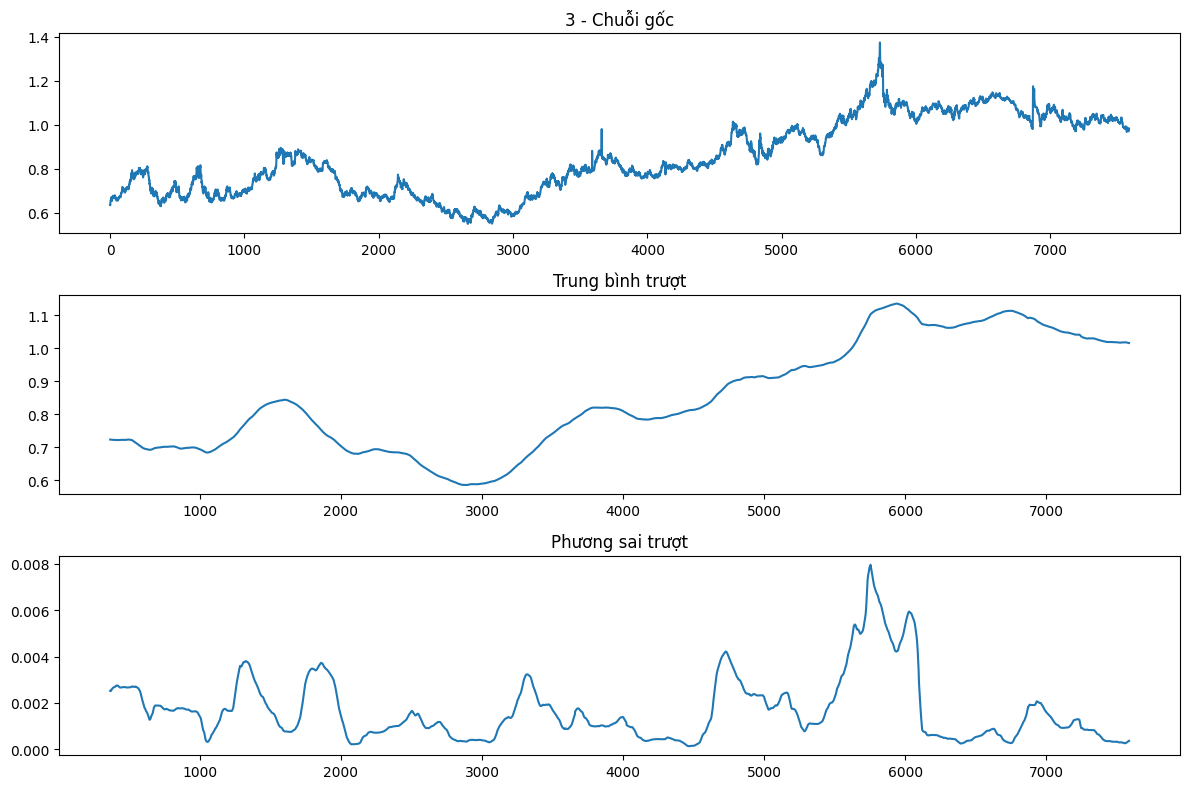

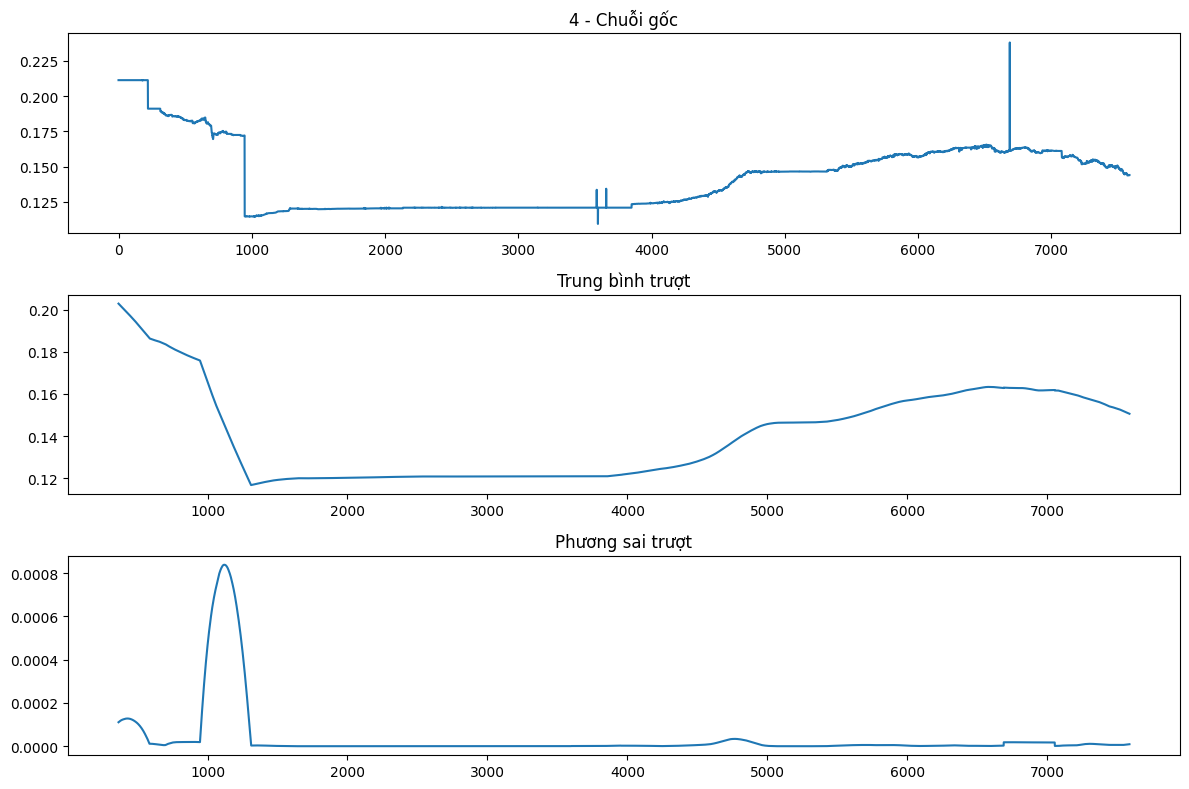

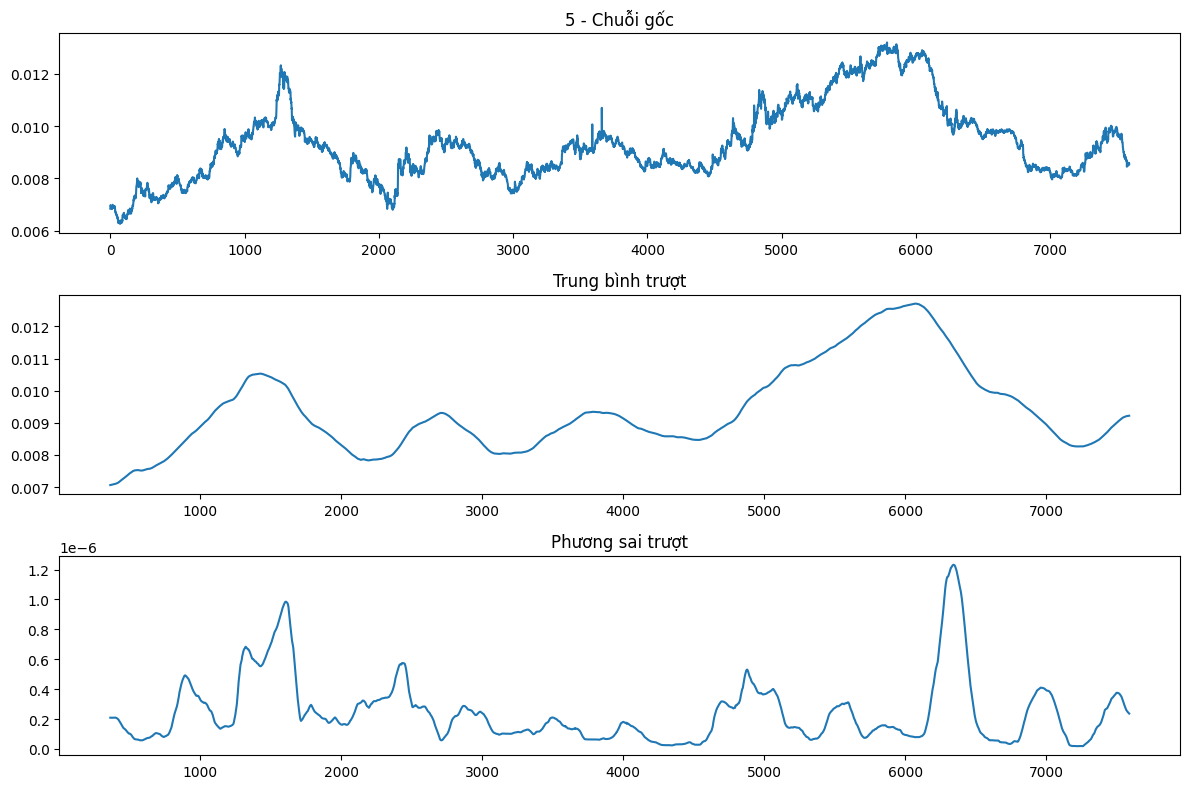

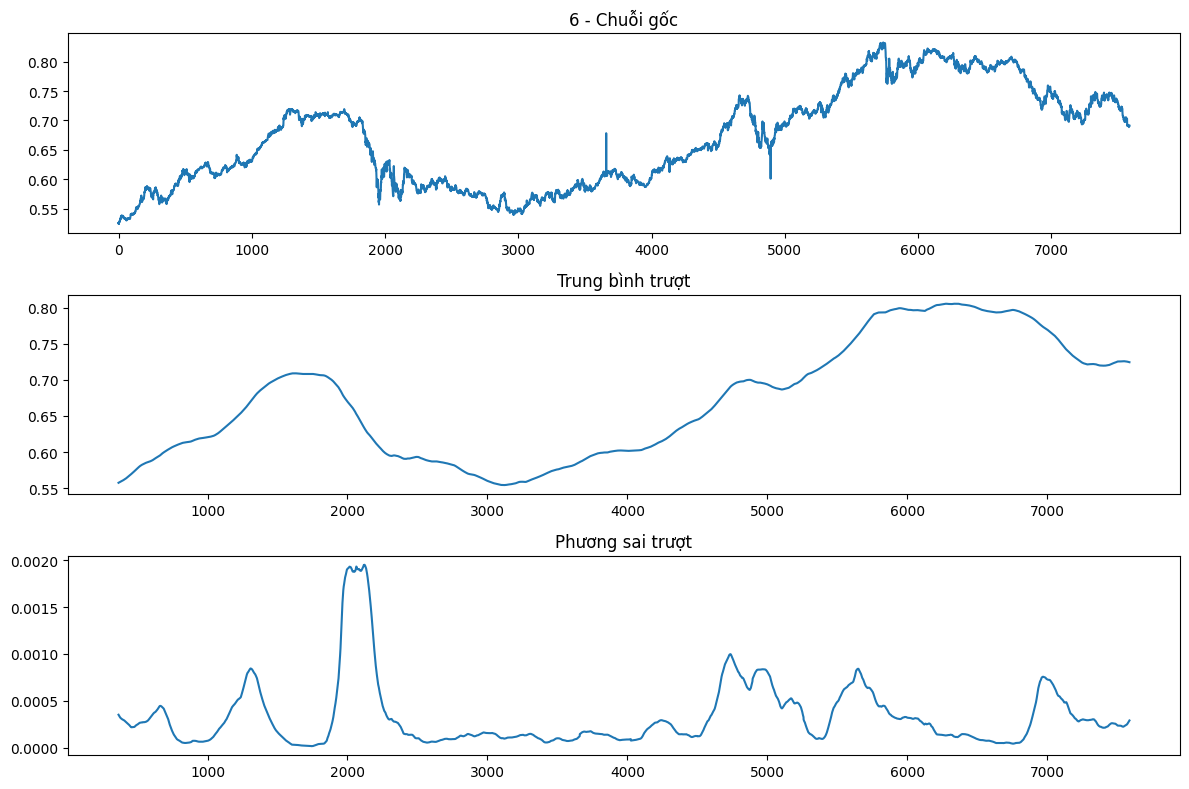

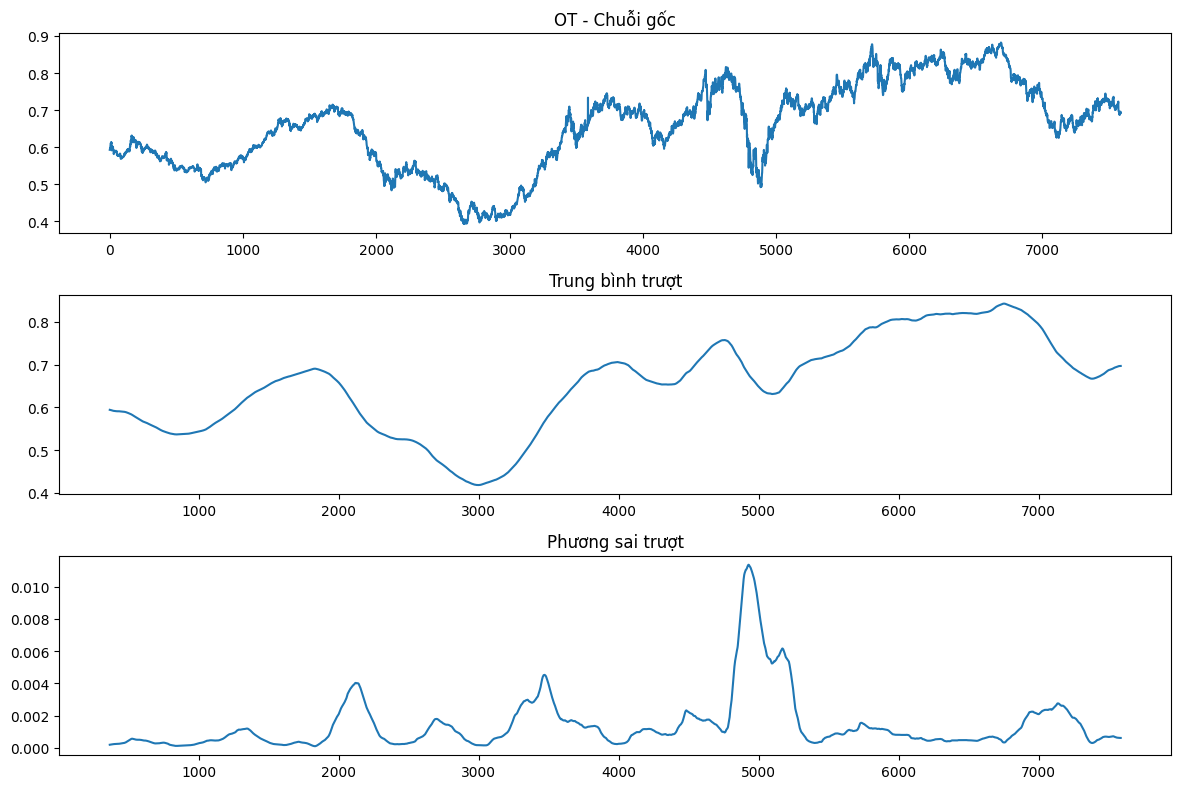

In [17]:
import pandas as pd
import matplotlib.pyplot as plt


# Điều chỉnh nếu tên cột thời gian của file khác
df = df.drop(columns=["date"], errors="ignore")

window = 365  # Cửa sổ 365 quan sát

for col in df.columns:
    series = pd.to_numeric(df[col], errors="coerce").dropna()

    rolling_mean = series.rolling(window).mean()
    rolling_var = series.rolling(window).var()

    fig, axes = plt.subplots(3, 1, figsize=(12, 8))

    axes[0].plot(series)
    axes[0].set_title(f"{col} - Chuỗi gốc")

    axes[1].plot(rolling_mean)
    axes[1].set_title("Trung bình trượt")

    axes[2].plot(rolling_var)
    axes[2].set_title("Phương sai trượt")

    plt.tight_layout()
    plt.show()